# 01 · Données LYCOS-IDS2017 : exploration et qualité

**Date :** 21 octobre 2026

**Ce qui est fait :**
1. Chargement des 5 jours étiquetés (`data/raw/lycos_labelled/`) avec les bons types (`timestamp` en float64, caractéristiques en float32).
2. Contrôle qualité par jour : flux, valeurs manquantes, infinies, doublons.
3. Répartition des classes par jour et rôle de chaque jour dans le découpage temporel.
4. Unité et plage de `timestamp`, chronologie des attaques.
5. Caractéristiques constantes et IP sources des attaques (justifie leur exclusion).

**Pourquoi :** connaître les données avant la préparation (notebook 02), vérifier qu'aucune attaque du test n'apparaît dans train/val, et repérer les pièges (fuite par IP, colonnes inutiles).

Rien n'est écrit dans `data/processed/` ici ; seules les figures vont dans `reports/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "src"))
from isocrates.ml.data import (DAYS, ID_COLS, LABEL, BENIGN, TS, TS_PER_SECOND,
                               ROOT, feature_columns, load_day, read_header)

REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

## 1. Colonnes

In [2]:
cols = read_header()
features = feature_columns(cols)
print(f"{len(cols)} colonnes : {len(ID_COLS)} identifiants/cible, {len(features)} caractéristiques")
print("Identifiants (jamais caractéristiques) :", ID_COLS)
print("Caractéristiques :", features)

83 colonnes : 6 identifiants/cible, 77 caractéristiques
Identifiants (jamais caractéristiques) : ['flow_id', 'src_addr', 'src_port', 'dst_addr', 'timestamp', 'label']
Caractéristiques : ['dst_port', 'ip_prot', 'flow_duration', 'down_up_ratio', 'pkt_len_max', 'pkt_len_min', 'pkt_len_mean', 'pkt_len_var', 'pkt_len_std', 'bytes_per_s', 'pkt_per_s', 'fwd_pkt_per_s', 'bwd_pkt_per_s', 'fwd_pkt_cnt', 'fwd_pkt_len_tot', 'fwd_pkt_len_max', 'fwd_pkt_len_min', 'fwd_pkt_len_mean', 'fwd_pkt_len_std', 'fwd_pkt_hdr_len_tot', 'fwd_pkt_hdr_len_min', 'fwd_non_empty_pkt_cnt', 'bwd_pkt_cnt', 'bwd_pkt_len_tot', 'bwd_pkt_len_max', 'bwd_pkt_len_min', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'bwd_pkt_hdr_len_tot', 'bwd_pkt_hdr_len_min', 'bwd_non_empty_pkt_cnt', 'iat_max', 'iat_min', 'iat_mean', 'iat_std', 'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_min', 'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min', 'bwd_iat_mean', 'bwd_iat_std', 'active_max', 'active_min', 'active_mean', 'active_std', 

## 2. Qualité et classes, jour par jour

Un jour est chargé à la fois (RAM : 9,7 Go). On garde seulement `timestamp`, `label`, `src_addr` pour la suite, et des statistiques min/max par caractéristique.

In [3]:
quality, keep, stats = [], [], {}
for day, (fname, role) in DAYS.items():
    df = load_day(day)
    x = df[features]
    quality.append({
        "jour": day, "rôle": role, "flux": len(df),
        "manquantes": int(df.isna().sum().sum()),
        "infinies": int(np.isinf(x.to_numpy()).sum()),
        "doublons": int(df.duplicated(subset=cols).sum()),
        "attaques": int((df[LABEL] != BENIGN).sum()),
        "Mo en RAM": round(df.memory_usage(deep=True).sum() / 1e6),
    })
    stats[day] = x.agg(["min", "max"]).T
    keep.append(df[["day", TS, LABEL, "src_addr"]])
    del df, x

flows = pd.concat(keep, ignore_index=True)
flows[LABEL] = flows[LABEL].astype("category")
quality = pd.DataFrame(quality).set_index("jour")
quality.loc["total"] = quality.sum(numeric_only=True)
quality

,rôle,flux,manquantes,infinies,doublons,attaques,Mo en RAM
jour,,,,,,,
lun,train/val,367181.0,0.0,0.0,0.0,0.0,153.0
mar,train/val,319637.0,0.0,0.0,0.0,6962.0,133.0
mer,train/val,495237.0,0.0,0.0,0.0,176304.0,206.0
jeu,test,112481.0,0.0,0.0,0.0,2033.0,47.0
ven,test,542962.0,0.0,0.0,0.0,256524.0,225.0
total,NaN,1837498.0,0.0,0.0,0.0,441823.0,764.0


In [4]:
classes = pd.crosstab(flows[LABEL], flows["day"]).reindex(columns=list(DAYS))
classes["total"] = classes.sum(axis=1)
classes = classes.sort_values("total", ascending=False)
classes

day,lun,mar,mer,jeu,ven,total
label,,,,,,
benign,367181,312675,318933,110448,286438,1395675
portscan,0,0,0,0,160106,160106
dos_hulk,0,0,158988,0,0,158988
ddos,0,0,0,0,95683,95683
dos_goldeneye,0,0,6765,0,0,6765
dos_slowloris,0,0,5674,0,0,5674
dos_slowhttptest,0,0,4866,0,0,4866
ftp_patator,0,4003,0,0,0,4003
ssh_patator,0,2959,0,0,0,2959


In [5]:
# Vérification clé : aucune attaque du test (jeu, ven) n'apparaît dans train/val (lun, mar, mer)
train_days = [d for d, (_, r) in DAYS.items() if r != "test"]
test_days = [d for d, (_, r) in DAYS.items() if r == "test"]
seen = set(flows.loc[flows.day.isin(train_days), LABEL].unique()) - {BENIGN}
unseen = set(flows.loc[flows.day.isin(test_days), LABEL].unique()) - {BENIGN}
print("Attaques en train/val :", sorted(seen))
print("Attaques en test      :", sorted(unseen))
print("Intersection          :", sorted(seen & unseen) or "aucune")

Attaques en train/val : ['dos_goldeneye', 'dos_hulk', 'dos_slowhttptest', 'dos_slowloris', 'ftp_patator', 'heartbleed', 'ssh_patator']
Attaques en test      : ['bot', 'ddos', 'portscan', 'webattack_bruteforce', 'webattack_sql_injection', 'webattack_xss']
Intersection          : aucune


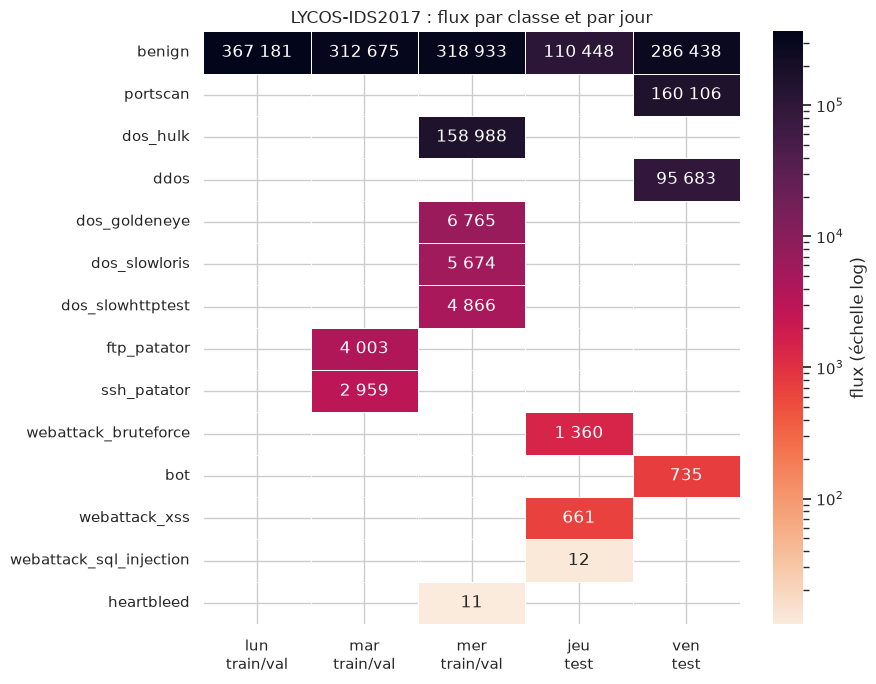

In [6]:
from matplotlib.colors import LogNorm
counts = classes.drop(columns="total")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(counts.replace(0, np.nan), annot=counts.map(lambda v: f"{v:,}".replace(",", " ") if v else ""),
            fmt="", norm=LogNorm(), cmap="rocket_r", cbar_kws={"label": "flux (échelle log)"},
            linewidths=0.5, linecolor="white", ax=ax)
ax.set_xticklabels([f"{d}\n{DAYS[d][1]}" for d in counts.columns], rotation=0)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("LYCOS-IDS2017 : flux par classe et par jour")
fig.tight_layout()
fig.savefig(REPORTS / "01_attaques_par_jour.png", dpi=150)
plt.show()

## 3. `timestamp` : unité et plage

Valeurs de 16 chiffres (environ 1,5·10¹⁵) : microsecondes Unix. Elles restent exactes en float64 (< 2⁵³ ≈ 9·10¹⁵).

In [7]:
flows["time"] = pd.to_datetime(flows[TS], unit="us", utc=True)
span = flows.groupby("day", sort=False).agg(
    début=("time", "min"), fin=("time", "max"), flux=(TS, "size"),
    trié=(TS, lambda t: t.is_monotonic_increasing),
    entiers=(TS, lambda t: bool((t % 1 == 0).all())))
span["durée"] = span["fin"] - span["début"]
span

,début,fin,flux,trié,entiers,durée
day,,,,,,
lun,2017-07-03 11:56:37.567312+00:00,2017-07-03 20:01:34.164007+00:00,367181,True,True,0 days 08:04:56.596695
mar,2017-07-04 11:53:44.398274+00:00,2017-07-04 20:00:30.041663+00:00,319637,True,True,0 days 08:06:45.643389
mer,2017-07-05 11:42:42.084372+00:00,2017-07-05 20:07:59.170242+00:00,495237,True,True,0 days 08:25:17.085870
jeu,2017-07-06 11:59:00.490140+00:00,2017-07-06 14:59:58.708313+00:00,112481,True,True,0 days 03:00:58.218173
ven,2017-07-07 11:59:50.315195+00:00,2017-07-07 20:02:39.567285+00:00,542962,True,True,0 days 08:02:49.252090


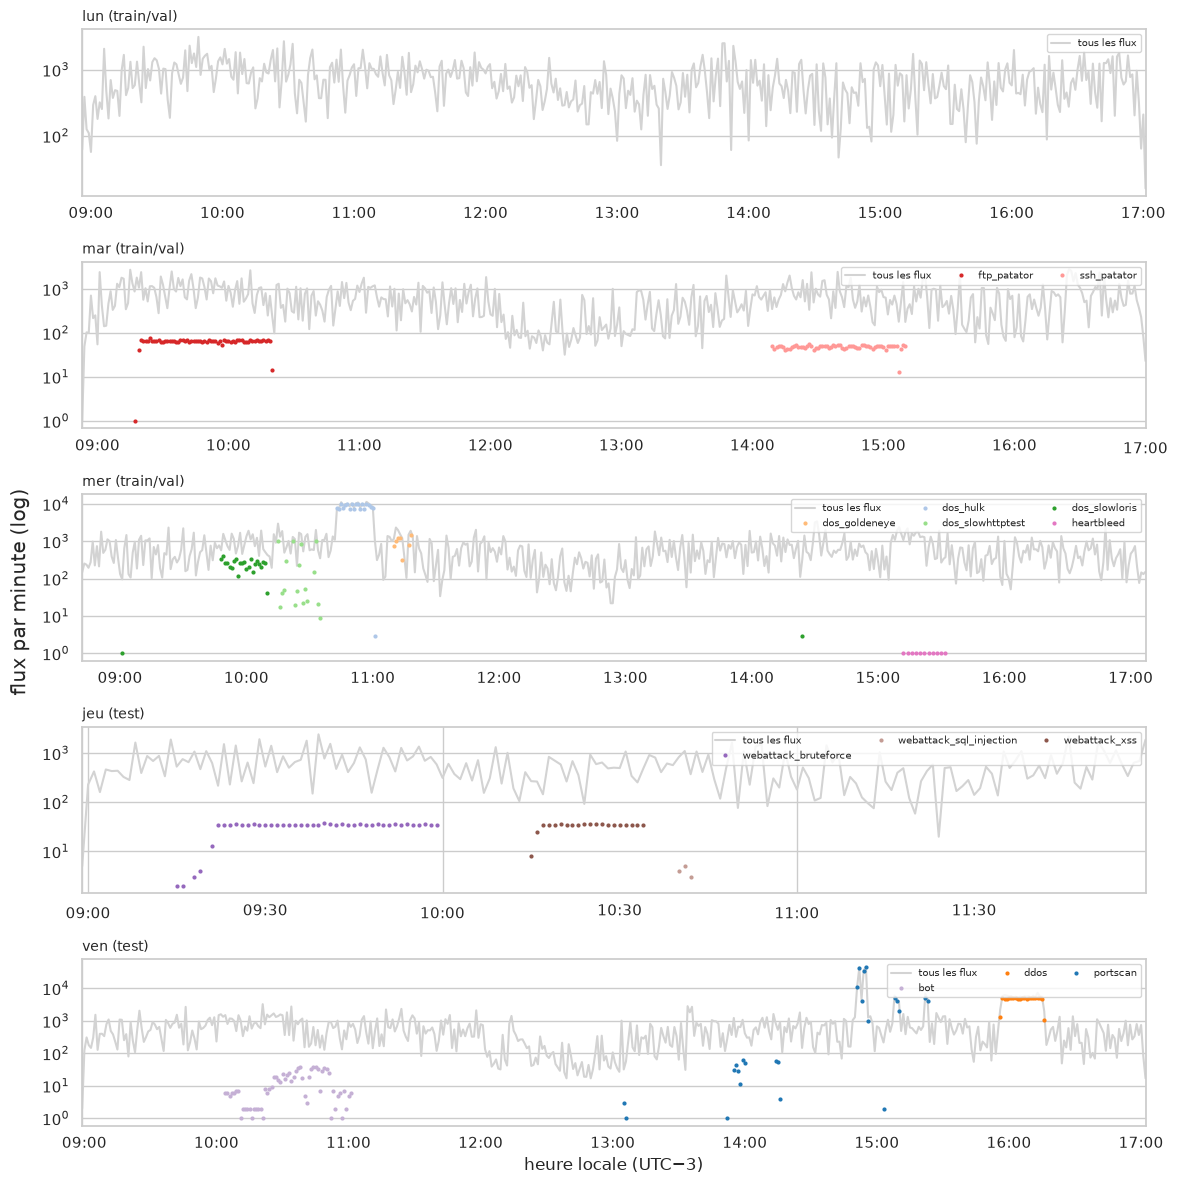

In [8]:
# Chronologie : attaques par minute, en heure locale du banc d'essai (Nouveau-Brunswick, UTC-3 en juillet)
flows["minute"] = flows["time"].dt.tz_convert("America/Halifax").dt.floor("min")
att = flows[flows[LABEL] != BENIGN]
labels = [l for l in classes.index if l != BENIGN]
palette = dict(zip(labels, sns.color_palette("tab20", len(labels))))

fig, axes = plt.subplots(len(DAYS), 1, figsize=(12, 12))
for ax, day in zip(axes, DAYS):
    d = flows[flows.day == day]
    d.groupby("minute").size().plot(ax=ax, color="lightgrey", label="tous les flux")
    a = att[att.day == day]
    for lab, g in a.groupby(LABEL, observed=True):
        # points (pas de ligne) : une ligne relierait à tort des minutes sans attaque
        g.groupby("minute").size().plot(ax=ax, color=palette[lab], label=lab, style=".", ms=4)
    ax.set_yscale("log")
    ax.set_title(f"{day} ({DAYS[day][1]})", loc="left", fontsize=10)
    ax.set_xlabel("")
    ax.legend(fontsize=7, loc="upper right", ncol=3)
axes[-1].set_xlabel("heure locale (UTC−3)")
fig.supylabel("flux par minute (log)")
fig.tight_layout()
fig.savefig(REPORTS / "01_chronologie_attaques.png", dpi=150)
plt.show()

In [9]:
# Fenêtre d'activité de chaque attaque (heure locale) ; les quantiles 1 % / 99 % écartent les flux isolés
hm = lambda t: t.strftime("%H:%M")
q = lambda p: (lambda s: hm(s.quantile(p)))
att.groupby(["day", LABEL], observed=True)["minute"].agg(
    début=lambda s: hm(s.min()), q01=q(0.01), q99=q(0.99), fin=lambda s: hm(s.max()), flux="size"
).sort_values(["day", "q01"], key=lambda c: c.map(list(DAYS).index) if c.name == "day" else c)

début    q01    q99    fin    flux
day label                                                      
mar ftp_patator              09:17  09:19  10:19  10:20    4003
    ssh_patator              14:09  14:09  15:10  15:10    2959
mer dos_slowloris            09:01  09:48  10:09  14:24    5674
    dos_slowhttptest         10:15  10:15  10:33  10:35    4866
    dos_hulk                 10:43  10:43  11:00  11:01  158988
    dos_goldeneye            11:10  11:10  11:18  11:18    6765
    heartbleed               15:12  15:12  15:31  15:32      11
jeu webattack_bruteforce     09:15  09:21  09:59  09:59    1360
    webattack_xss            10:15  10:15  10:34  10:34     661
    webattack_sql_injection  10:40  10:40  10:42  10:42      12
ven bot                      10:04  10:05  11:00  11:01     735
    portscan                 13:05  14:51  15:23  15:23  160106
    ddos                     15:56  15:56  16:16  16:16   95683

## 4. Aperçu du découpage 80/20 : où tombent les attaques ?

Deux lectures possibles de la règle « train = 80 % les plus anciens de lun, mar, mer » :
- **par jour** : les 80 % les plus anciens de chaque jour, les 20 % restants de chaque jour en val ;
- **global** : les 80 % les plus anciens des trois jours mis bout à bout (lun puis mar puis mer).

On compte les attaques de chaque classe dans train et val pour les deux lectures.

In [10]:
tv = flows[flows.day.isin(train_days)].copy()
cut_day = tv.groupby("day")[TS].transform(lambda t: t.quantile(0.8))
tv["par jour"] = np.where(tv[TS] <= cut_day, "train", "val")
tv["global"] = np.where(tv[TS] <= tv[TS].quantile(0.8), "train", "val")

split = pd.concat({k: pd.crosstab(tv[LABEL], tv[k]) for k in ["par jour", "global"]}, axis=1)
split = split.loc[split.index.isin(seen | {BENIGN})]
split

par jour          global        
par jour            train     val   train     val
label                                            
benign             762388  236401  777738  221051
dos_goldeneye        6765       0       0    6765
dos_hulk           158988       0  150407    8581
dos_slowhttptest     4866       0    4866       0
dos_slowloris        5674       0    5671       3
ftp_patator          4003       0    4003       0
heartbleed              0      11       0      11
ssh_patator          2959       0    2959       0

In [11]:
# Heure locale des coupures
loc = lambda t: pd.to_datetime(t, unit="us", utc=True).tz_convert("America/Halifax").strftime("%a %H:%M")
print("Coupure par jour :", {d: loc(c) for d, c in tv.groupby("day")[TS].quantile(0.8).items()})
print("Coupure globale  :", loc(tv[TS].quantile(0.8)))

Coupure par jour : {'lun': 'Mon 15:15', 'mar': 'Tue 15:22', 'mer': 'Wed 14:34'}
Coupure globale  : Wed 10:59


## 5. Caractéristiques constantes

Une caractéristique constante (min = max) sur train/val n'apporte rien au modèle : candidate à la suppression dans le notebook 02. Décision prise sur lun/mar/mer uniquement (règle 7).

In [12]:
tr = pd.concat([stats[d] for d in train_days], axis=1, keys=train_days)
tr_min = tr.xs("min", axis=1, level=1).min(axis=1)
tr_max = tr.xs("max", axis=1, level=1).max(axis=1)
const_train = tr_min[tr_min == tr_max].index.tolist()
print(f"Constantes sur train/val ({len(const_train)}) :", const_train)

te = pd.concat([stats[d] for d in test_days], axis=1, keys=test_days)
te_min = te.xs("min", axis=1, level=1).min(axis=1)
te_max = te.xs("max", axis=1, level=1).max(axis=1)
print("Valeurs sur test pour ces colonnes :")
pd.DataFrame({"train min=max": tr_min[const_train], "test min": te_min[const_train], "test max": te_max[const_train]})

Constantes sur train/val (3) : ['flag_urg', 'fwd_flag_urg', 'bwd_flag_urg']
Valeurs sur test pour ces colonnes :


,train min=max,test min,test max
flag_urg,0.0,0.0,0.0
fwd_flag_urg,0.0,0.0,0.0
bwd_flag_urg,0.0,0.0,0.0


## 6. IP sources des attaques

Si chaque attaque vient de quelques IP fixes, un modèle qui verrait `src_addr` apprendrait l'IP et non le comportement : c'est pourquoi IP et ports source sont exclus des caractéristiques (règle 4).

In [13]:
ip = att.groupby(LABEL, observed=True)["src_addr"].agg(
    ip_distinctes="nunique",
    ip_principale=lambda s: s.value_counts().index[0],
    part_ip_principale=lambda s: round(s.value_counts(normalize=True).iloc[0], 3))
ip.sort_values("ip_distinctes")

,ip_distinctes,ip_principale,part_ip_principale
label,,,
ddos,1,172.16.0.1,1.0
dos_goldeneye,1,172.16.0.1,1.0
dos_hulk,1,172.16.0.1,1.0
dos_slowhttptest,1,172.16.0.1,1.0
ftp_patator,1,172.16.0.1,1.0
dos_slowloris,1,172.16.0.1,1.0
heartbleed,1,172.16.0.1,1.0
portscan,1,172.16.0.1,1.0
webattack_xss,1,172.16.0.1,1.0


In [14]:
# Trafic benign émis par ces IP : si presque nul, l'IP seule « détecte » l'attaque (fuite)
ben = flows[flows[LABEL] == BENIGN]
pd.DataFrame({
    "flux benign": ben.src_addr.value_counts().reindex(ip["ip_principale"].unique(), fill_value=0),
    "flux attaque": att.src_addr.value_counts().reindex(ip["ip_principale"].unique(), fill_value=0),
}).assign(part_benign=lambda d: (d["flux benign"] / (d["flux benign"] + d["flux attaque"])).round(4))

,flux benign,flux attaque,part_benign
src_addr,,,
192.168.10.15,115575,220,0.9981
172.16.0.1,1383,441088,0.0031


## Observations

1. **Volume et qualité.** 1 837 498 flux, 83 colonnes dont 77 caractéristiques. 0 valeur manquante, 0 infinie, **0 doublon** quand `timestamp` est lu en float64 (les 11 « doublons » vus par `explore.py` venaient vraisemblablement du cast en float32, qui rend égaux des timestamps proches).
2. **Déséquilibre.** 441 823 attaques (24 % des flux), très inégales : de 160 106 (portscan) à 11 (heartbleed) et 12 (sql_injection). Métriques par classe obligatoires ; les classes à une dizaine de flux ne donneront pas de chiffre stable.
3. **Aucune attaque du test n'est vue en train/val** (intersection vide) : le RF ne pourra pas étiqueter correctement bot, ddos, portscan ni les attaques web ; c'est le rôle du détecteur d'anomalies.
4. **`timestamp`** : microsecondes Unix UTC, entiers exacts en float64, déjà triés dans chaque fichier. Journées de 9 h à 17 h heure locale (UTC−3), sauf jeudi limité à 9 h–12 h (après-midi d'infiltration retiré).
5. **Découpage 80/20 : la validation ne contient presque pas d'attaques.** Par jour, val = 236 401 benign + 11 heartbleed ; en global, val = fin de mercredi (6 765 goldeneye, 8 581 hulk, 11 heartbleed, 3 slowloris) mais ni ftp, ni ssh, ni slowhttptest. Le seuil des détecteurs d'anomalies (99e percentile du benign de val) reste possible, mais le réglage du RF/MLP sur val ne l'est pas tel quel : **décision à prendre avant le notebook 02.**
6. **Caractéristiques constantes** sur train/val : `flag_urg`, `fwd_flag_urg`, `bwd_flag_urg` (toujours 0, aussi en test) → à retirer.
7. **Fuite par IP confirmée.** 12 des 13 classes d'attaque viennent d'une seule IP, `172.16.0.1` (la passerelle de l'attaquant), qui n'émet que 0,3 % de trafic benign (1 383 flux sur 442 471). Un modèle voyant `src_addr` « détecterait » l'IP. Seul bot vient de 5 postes internes (`192.168.10.x`) au trafic surtout benign. Règle 4 justifiée.
8. **Bords d'étiquetage.** Quelques flux isolés sont étiquetés hors de la fenêtre principale de l'attaque (ex. 4 flux dos_slowloris à 9 h 01 et 14 h 24, cœur 9 h 48–10 h 09). Le portscan commence par des flux épars dès 13 h 05 avant sa phase intense de 14 h 51 à 15 h 23.